# Scaling relations in self-affine time series

This notebook tests relations among correlation, spectrum, DFA, wavelets and graph roughness. Bibliographic metadata appear in `../article/references.bib`.

We use $H\in\{0.1,0.2,\ldots,0.9\}$, $N\in\{2^{10},2^{12},2^{14},2^{16}\}$, and $M=200$. The duplicate $0.1$ and terminal $1.0$ in the task are treated as a typo and a degenerate boundary: standard fBm/fGn uses $0<H<1$ [Mandelbrot & Van Ness, 1968]. Fixed random seeds make each run reproducible. For plots, frequency and time are in inverse-sample and sample units.

## Mathematical conventions and scope

Let $B_H(t)$ be fBm, with $\operatorname{Var}[B_H(t+\tau)-B_H(t)]=|\tau|^{2H}$ and stationary increments $X_k=B_H(k+1)-B_H(k)$ (fGn) [Mandelbrot & Van Ness, 1968]. We generate fGn from
$$\gamma_H(k)=\tfrac12\{|k+1|^{2H}-2|k|^{2H}+|k-1|^{2H}\}$$
using circulant embedding [Davies & Harte, 1987; Wood & Chan, 1994], then cumulatively sum it for fBm. For $H>1/2$, $\gamma_H(k)\sim H(2H-1)k^{2H-2}$, so the positive ACF tail has $\beta=2-2H\in(0,1)$. For $H<1/2$, the coefficient is negative, $\beta>1$, and the covariance is absolutely summable: the task's statement to the contrary is incorrect. A positive-ACF log fit is therefore restricted to $H>1/2$. Aggregated variance supplies an alternative across the full $H$ range.

With $S(f)\sim f^{-\alpha}$ at low frequency, fGn has $\alpha_g=2H-1$; the cumulative path has a formal finite-record spectral slope $\alpha_B=\alpha_g+2=2H+1$. fBm is nonstationary, so this last relation concerns Fourier scaling of finite paths, not a stationary Wiener–Khinchin spectrum. For fBm paths $D=2-H=(5-\alpha_B)/2$. Combining the fGn covariance exponent with this path dimension yields $D=1+\beta/2$. A continuous-time stationary increment field $X_H(t)=B_H(t+1)-B_H(t)$ also has local graph dimension $2-H$ [Gneiting & Schlather, 2004], which explains the task's fGn label. Here $D$ is estimated on the cumulative fBm path; an isolated discrete fGn sequence has no continuous graph dimension without a specified interpolation or underlying process.

For $0<\beta<1$, $\int_0^\infty k^{-\beta}\cos(2\pi fk)\,dk=\Gamma(1-\beta)\sin(\pi\beta/2)(2\pi f)^{\beta-1}$ gives $\alpha_g=1-\beta$. This positive-tail argument does not apply unchanged when $H<1/2$. There the fGn covariance is absolutely summable but its total sum vanishes, canceling the spectral constant and leaving $S(f)\propto f^{1-2H}$. At $H=1/2$ there is no nonzero-lag covariance power law; $\beta=1$ denotes the aggregated-variance slope $\operatorname{Var}(\bar X_s)\propto s^{-1}$, not an ACF exponent. A covering heuristic for the path uses $\epsilon^{-1}$ time strips and $\epsilon^{H-1}$ vertical boxes per strip, yielding $D=2-H$; the rigorous fBm graph result is documented by Harte (2001).

The local increment standard deviation $\sigma_\tau=\operatorname{sd}(B_H(t+\tau)-B_H(t))\propto\tau^H$ is our structure estimator. The local report by Ronquillo Nuñez (2026) uses this same slope on the input series, obtaining nearly zero for white noise itself. Here white noise is fGn with $H=1/2$ and its cumulative path is ordinary Brownian motion; these are different input conventions. The report has no journal, publisher or DOI identified.

## Estimators

DFA first forms $Y(i)=\sum_{k=1}^i(x_k-\bar x)$, fits a polynomial separately in each length-$s$ segment, and computes $F(s)=\{(2N_s s)^{-1}\sum_{\nu,i}[Y_\nu(i)-p_\nu(i)]^2\}^{1/2}$. The slope $F(s)\sim s^{\alpha_{\rm DFA}}$ estimates $H$ for fGn; applying DFA to fBm directly gives $H+1$. We use DFA1 (linear trend in the profile), two-sided segmenting, and scales $16$ to $N/8$ [Peng et al., 1994; Kantelhardt et al., 2002]. For strongly antipersistent inputs, finite-scale DFA can be biased; Chen et al. (2002) recommend an additional integration and reading the slope of $F(s)/s$. We retain the raw DFA1 estimate and examine its finite-sample bias.

Periodogram and Welch fits use $\max(4/N,1/4096)\le f\le1/8$. Wavelet detail variances at dyadic scale $2^j$ obey $\operatorname{Var}(d_j)\propto 2^{j\alpha_w}$ for a stationary fGn in this normalization, so $\alpha_w=2H-1$ [Abry & Veitch, 1998]. The structure function and R/S estimate $H$ independently; R/S is reported as an empirical comparator. Aggregated variance fits $\operatorname{Var}(\bar X_s)\propto s^{2H-2}=s^{-\beta}$. Higuchi length scales as $L(k)\propto k^{-D}$ [Higuchi, 1988], and graph box counts scale as $N(\epsilon)\propto\epsilon^{-D}$. Both geometric estimators run on fBm paths.

We also fit wavelet detail variance on the fBm path to examine $\alpha_{w,B}=2H+1$. Because a finite nonstationary path creates large boundary coefficients, this fit uses symmetric extension and excludes four coefficients at each end of every detail band. We retain levels with at least 32 coefficients and report the resulting finite-record bias separately from the fGn wavelet fit.

Kantelhardt et al. (2002) define $F_q(s)$ and $h(q)$ for MF-DFA; at $q=2$ it reduces to DFA. The present objectives concern monofractal scaling and estimator domains, so $q\ne2$ is not analyzed. Their $\tau(q)=qh(q)-1$ relation is not needed here.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from analysis import (davies_harte, spectral_synthesis, lorentzian_synthesis, cauchy_process,
                      estimate_pair, summarize, all_relation_residuals, primary_relation_residuals,
                      dfa, spectral_alpha,
                      structure_h, higuchi_dimension, aggregate_beta)
RESULTS = ROOT / 'results'; FIGURES = ROOT / 'article' / 'figures'
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
SEED = 20261105
H_VALUES = np.round(np.arange(.1, 1., .1), 1)
N_VALUES = (2**10, 2**12, 2**14, 2**16)
M = 200

## Small controlled check

We inspect one $H=0.7$, $N=4096$ path before running the grid. The expected fGn spectrum slope is $0.4$, fBm graph dimension $1.3$, and DFA slope $0.7$; finite records will differ.

In [2]:
rng = np.random.default_rng(SEED)
sample_g = davies_harte(4096, .7, rng)
sample_b = np.r_[0., np.cumsum(sample_g)]
pilot = estimate_pair(sample_g, sample_b, .7)
display(pd.Series(pilot).to_frame('estimate').round(3))
assert .35 < pilot['H_dfa'] < 1.05

,estimate
H_dfa,0.657
H_rs,0.708
H_structure,0.642
beta_acf,0.768
beta_aggregate,0.759
alpha_periodogram,0.380
alpha_welch,0.337
alpha_wavelet,0.315
alpha_wavelet_fbm,2.390
alpha_fbm,2.327


## Reference experiment

Each realization pairs the stationary fGn sequence and its fBm path. Fourier synthesis is a second generator: it creates a periodic finite sequence with a prescribed discrete spectral envelope rather than an exact fGn covariance. We keep its results separate from Davies–Harte. Failed fits are recorded as missing values.

In [3]:
rows = []
rng = np.random.default_rng(SEED + 1)
for process in ('Davies-Harte', 'Fourier synthesis'):
    for n in N_VALUES:
        for h in H_VALUES:
            for replicate in range(M):
                x = (davies_harte(n, h, rng) if process == 'Davies-Harte'
                     else spectral_synthesis(n, 2*h-1, rng))
                path = np.r_[0., np.cumsum(x)]
                rows.append(dict(process=process, H=h, N=n, replicate=replicate,
                                 **estimate_pair(x, path, h)))
estimates = pd.DataFrame(rows)
estimates.to_csv(RESULTS / 'estimates.csv', index=False)
summary = summarize(estimates)
summary.to_csv(RESULTS / 'summary.csv', index=False)
print(f'{len(estimates):,} paired realizations; {int(summary["count"].min())} minimum usable estimates per reported cell')
display(summary[(summary.process=='Davies-Harte') & (summary.N==2**14) &
                (summary.estimator.isin(['H_dfa','alpha_welch','D_higuchi']))]
        .pivot(index='H',columns='estimator',values='bias').round(3))

14,400 paired realizations; 200 minimum usable estimates per reported cell


estimator,D_higuchi,H_dfa,alpha_welch
H,,,
0.1,-0.000,0.007,-0.161
0.2,0.000,0.003,-0.065
0.3,0.001,0.002,-0.029
0.4,0.001,-0.001,-0.011
0.5,0.001,-0.003,-0.006
0.6,0.001,-0.003,0.002
0.7,0.000,-0.003,0.003
0.8,0.001,-0.003,0.005
0.9,0.006,-0.003,0.005


## Relation residuals and uncertainty

For each paired realization we evaluate eight distinct identities: $\beta=2-2H$, $\alpha_g=1-\beta$, $\alpha_B=\alpha_g+2$, $D=2-H$, $D=(5-\alpha_B)/2$, $D=1+\beta/2$, $\alpha_{w,g}=\alpha_g$, and $\alpha_{w,B}=\alpha_B$. We estimate $H$ with DFA on fGn; thus $\beta=2-2\alpha_{\mathrm{DFA}}$ is the first identity. The task's three example residuals are a subset of these eight. For each mean residual, 5,000 paired bootstrap resamples give an *unadjusted* 95% percentile interval. Two-sided one-sample $t$ tests assess a zero mean across 200 independent realizations; their $p$ values receive Bonferroni adjustment over the single family of $2\times9\times4\times8=576$ tests. The 216 rows in `residuals.csv` are a view of this family and retain the same adjusted $p$ values. Rejection describes finite-sample estimator residuals, not the truth of the underlying process identity.

In [4]:
all_relations=all_relation_residuals(estimates,np.random.default_rng(SEED+5),reps=5000)
all_relations.to_csv(RESULTS/'all_relations.csv',index=False)
residuals=primary_relation_residuals(all_relations)
residuals.to_csv(RESULTS/'residuals.csv',index=False)
display(all_relations.groupby(['process','relation']).agg(
        mean_residual=('mean','mean'),rejection_rate=('reject_05','mean')).round(3))

mean_residual  rejection_rate
process           relation                                   
Davies-Harte      D_H                   0.002           0.222
                  D_alpha_B            -0.087           0.861
                  D_beta               -0.015           0.389
                  alpha_B_g            -0.138           0.611
                  alpha_g_beta         -0.005           0.667
                  beta_H                0.035           0.528
                  wavelet_B             0.118           0.806
                  wavelet_g            -0.001           0.361
Fourier synthesis D_H                   0.009           0.583
                  D_alpha_B            -0.077           0.833
                  D_beta               -0.011           0.583
                  alpha_B_g            -0.138           0.611
                  alpha_g_beta          0.006           0.639
                  beta_H                0.041           0.694
                  wavelet_B             0.120           0.806
                  wavelet_g             0.000           0.083

## Contrast processes

At $N=4096$ and $H=0.7$ we compare the reference to white-noise contamination, a linear trend, a sinusoid, a low-frequency cutoff in a Lorentzian-mixture $1/f$ spectrum, and a generalized Cauchy covariance. The Lorentzian mixture uses $S(f)\propto\int_{1/1024}^{1/2}(\lambda^2+f^2)^{-1}\,d\lambda$; its interior band behaves approximately as $1/f$ and its low-frequency end is flat [Dutta & Horn, 1981]. For the Cauchy model $C(k)=(1+|k|^{2H_\mathrm{loc}})^{-(1-H_\mathrm{glob})/H_\mathrm{loc}}$, small-lag roughness is controlled by $H_\mathrm{loc}=0.35$ while the large-lag memory parameter is $H_\mathrm{glob}=0.75$ [Gneiting & Schlather, 2004]. Integer-time graph estimates on this stationary process cannot resolve the $k\to0$ asymptote. The cutoff and Fourier constructions are finite-band approximations, not exact globally self-affine processes.

In [5]:
rng = np.random.default_rng(SEED + 3)
contrasts=[]
curve_rows=[]
nc=4096
for replicate in range(200):
    base=davies_harte(nc,.7,rng)
    t=np.arange(nc)
    variants={
        'reference':base,
        'additive white noise':base + .6*rng.standard_normal(nc),
        'linear trend':base + .0005*t,
        'periodic component':base + .8*np.sin(2*np.pi*t/128),
        'Lorentzian 1/f cutoff':lorentzian_synthesis(nc,rng),
        'Cauchy local/global':cauchy_process(nc,.35,.75,rng),
    }
    for name,x in variants.items():
        path=np.r_[0.,np.cumsum(x)]
        rough_path = x if name == 'Cauchy local/global' else path
        dfa_slope,scales,fluctuation=dfa(x,return_curve=True)
        assert scales[0]==16
        curve_rows.extend(dict(process=name,replicate=replicate,scale=int(scale),
                               fluctuation=float(value),normalized_fluctuation=float(value/fluctuation[0]))
                          for scale,value in zip(scales,fluctuation))
        contrasts.append(dict(process=name,replicate=replicate,
                              H_dfa=dfa_slope,alpha_welch=spectral_alpha(x,'welch'),
                              H_structure=structure_h(rough_path),
                              D_higuchi=higuchi_dimension(rough_path),
                              beta_aggregate=aggregate_beta(x)))
contrast=pd.DataFrame(contrasts)
contrast.to_csv(RESULTS/'contrasts.csv',index=False)
contrast_curves=pd.DataFrame(curve_rows)
contrast_curves.to_csv(RESULTS/'contrast_dfa_curves.csv',index=False)
display(contrast.groupby('process').agg(['mean','std']).round(3))

replicate          H_dfa        alpha_welch         \
                           mean     std   mean    std        mean    std   
process                                                                    
Cauchy local/global        99.5  57.879  0.862  0.040       0.775  0.057   
Lorentzian 1/f cutoff      99.5  57.879  0.945  0.042       0.973  0.053   
additive white noise       99.5  57.879  0.672  0.035       0.332  0.058   
linear trend               99.5  57.879  0.709  0.033       0.391  0.055   
periodic component         99.5  57.879  0.837  0.020       0.523  0.053   
reference                  99.5  57.879  0.697  0.035       0.391  0.055   

                      H_structure        D_higuchi        beta_aggregate  \
                             mean    std      mean    std           mean   
process                                                                    
Cauchy local/global         0.083  0.006     1.922  0.007          0.433   
Lorentzian 1/f cutoff       0.850  0.021     1.142  0.021          0.395   
additive white noise        0.660  0.027     1.326  0.029          0.686   
linear trend                0.870  0.016     1.035  0.008          0.168   
periodic component          0.718  0.018     1.179  0.009          0.783   
reference                   0.685  0.027     1.302  0.030          0.650   

                              
                         std  
process                       
Cauchy local/global    0.080  
Lorentzian 1/f cutoff  0.071  
additive white noise   0.089  
linear trend           0.029  
periodic component     0.084  
reference              0.092

### Contrast grid across $H$ and $N$

The additive, linear-trend, periodic and Cauchy contrasts also run at every requested $H$, $N$ and $M=200$ combination. The Cauchy local parameter remains $0.35$ and its global parameter follows the grid $H$; its graph and structure statistics use the stationary process itself. The Lorentzian mixture has no $H$ parameter, so only its 200-realization representative case is run. This extended grid records how the contrast effects depend on record length and baseline memory without assigning an artificial $H$ to the cutoff model.

For the Cauchy model with global $H<1/2$, its positive covariance tail is summable; block-mean variance then tends to $s^{-1}$, so the aggregated-variance slope need not recover its nominal tail exponent $2-2H>1$. The representative case with global $H=0.75$ has a nonsummable positive tail, for which this comparison is meaningful [Gneiting & Schlather, 2004].

In [6]:
grid_rows=[]
rng=np.random.default_rng(SEED+4)
for n in N_VALUES:
    t=np.arange(n)
    for h in H_VALUES:
        for replicate in range(M):
            base=davies_harte(n,h,rng)
            variants={
                'additive white noise':base+.6*rng.standard_normal(n),
                'linear trend':base+.0005*t,
                'periodic component':base+.8*np.sin(2*np.pi*t/128),
                'Cauchy local/global':cauchy_process(n,.35,h,rng),
            }
            for name,x in variants.items():
                rough=x if name=='Cauchy local/global' else np.r_[0.,np.cumsum(x)]
                grid_rows.append(dict(process=name,H=h,N=n,replicate=replicate,
                    H_dfa=dfa(x),H_structure=structure_h(rough),
                    alpha_welch=spectral_alpha(x,'welch'),
                    D_higuchi=higuchi_dimension(rough),
                    beta_aggregate=aggregate_beta(x)))
contrast_grid=pd.DataFrame(grid_rows)
contrast_grid.to_csv(RESULTS/'contrast_grid.csv',index=False)
print(f'{len(contrast_grid):,} contrast-grid realizations')
display(contrast_grid[(contrast_grid.H==.7)&(contrast_grid.N==2**12)]
        .groupby('process')[['H_dfa','H_structure','alpha_welch','D_higuchi']].mean().round(3))

28,800 contrast-grid realizations


,H_dfa,H_structure,alpha_welch,D_higuchi
process,,,,
Cauchy local/global,0.824,0.072,0.704,1.933
additive white noise,0.672,0.661,0.332,1.326
linear trend,0.710,0.872,0.394,1.035
periodic component,0.839,0.720,0.528,1.179


## Figures

Fit windows are fixed in advance. Their bounds are shown in the method text and the scale plot below. The figures are saved for direct inclusion in the article.

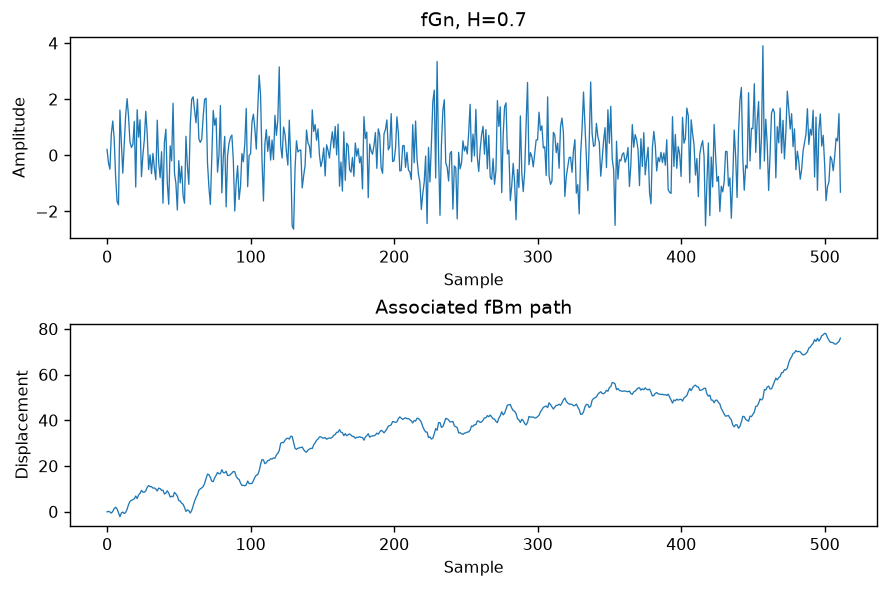

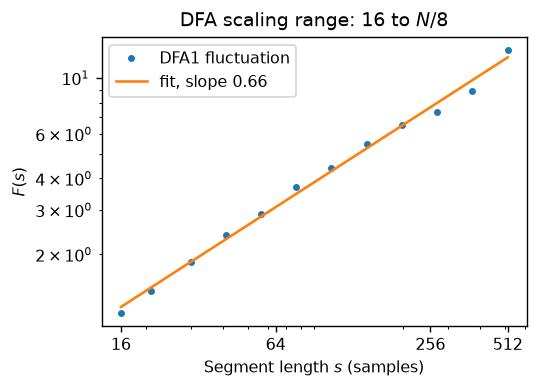

In [7]:
plt.rcParams.update({'font.size':9,'figure.dpi':125,'savefig.dpi':220})
fig,ax=plt.subplots(2,1,figsize=(7,4.6),layout='constrained')
ax[0].plot(sample_g[:512],lw=.75);ax[0].set(title='fGn, H=0.7',xlabel='Sample',ylabel='Amplitude')
ax[1].plot(sample_b[:512],lw=.75);ax[1].set(title='Associated fBm path',xlabel='Sample',ylabel='Displacement')
fig.savefig(FIGURES/'signals.pdf');plt.show()

exponent,s,f=dfa(sample_g,return_curve=True)
fig,ax=plt.subplots(figsize=(4.2,3.0),layout='constrained')
ax.loglog(s,f,'o',ms=3,label='DFA1 fluctuation')
ax.loglog(s,np.exp(np.polyfit(np.log(s),np.log(f),1)[1])*s**exponent,'-',label=f'fit, slope {exponent:.2f}')
ax.set(xlabel='Segment length $s$ (samples)',ylabel='$F(s)$',title='DFA scaling range: 16 to $N/8$')
ax.set_xticks([16,64,256,512],labels=['16','64','256','512'])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.legend();fig.savefig(FIGURES/'dfa_scaling.pdf');plt.show()

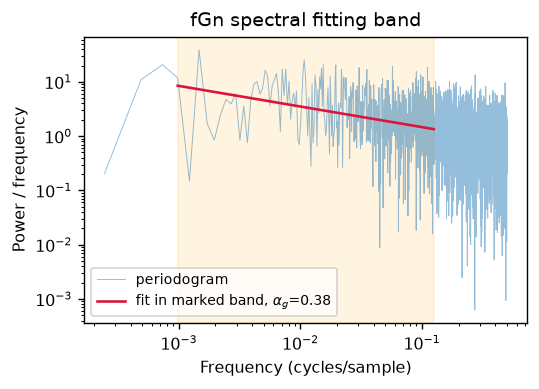

In [8]:
from scipy.signal import periodogram
freq,power=periodogram(sample_g,detrend='linear',window='boxcar')
band=(freq>=4/len(sample_g))&(freq<=1/8)&(power>0)
sl,inter=np.polyfit(np.log(freq[band]),np.log(power[band]),1)
fig,ax=plt.subplots(figsize=(4.2,3),layout='constrained')
ax.loglog(freq[1:],power[1:],lw=.55,alpha=.48,label='periodogram')
ax.loglog(freq[band],np.exp(inter)*freq[band]**sl,color='crimson',lw=1.5,
          label=f'fit in marked band, $\\alpha_g$={-sl:.2f}')
ax.axvspan(freq[band].min(),freq[band].max(),color='orange',alpha=.12)
ax.set(xlabel='Frequency (cycles/sample)',ylabel='Power / frequency',
       title='fGn spectral fitting band')
ax.legend(fontsize=8);fig.savefig(FIGURES/'spectral_fit.pdf');plt.show()

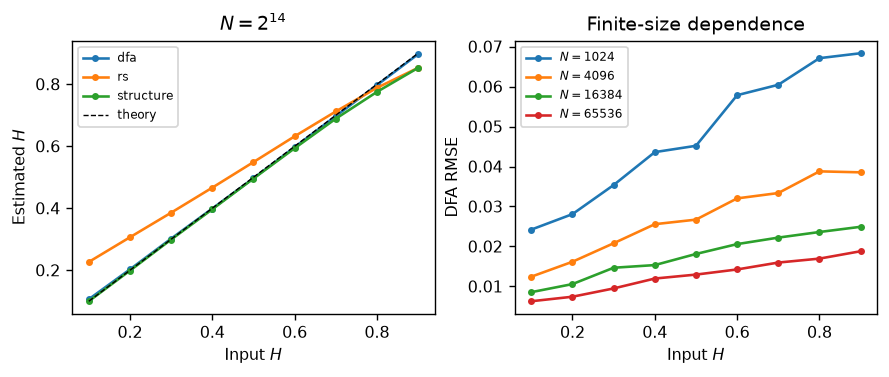

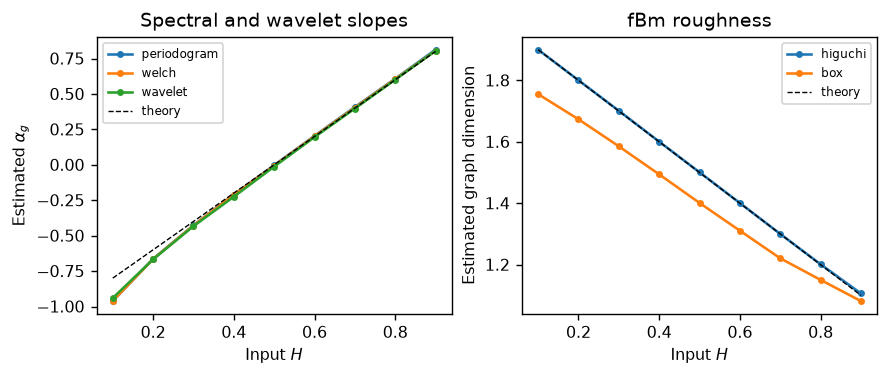

In [9]:
ref=summary[(summary.process=='Davies-Harte') & (summary.estimator.isin(['H_dfa','H_rs','H_structure']))]
fig,axs=plt.subplots(1,2,figsize=(7,2.9),layout='constrained')
for name,grp in ref.groupby('estimator'):
    g=grp[grp.N==2**14]
    axs[0].plot(g.H,g['mean'],'o-',ms=3,label=name.removeprefix('H_'))
axs[0].plot([.1,.9],[.1,.9],'k--',lw=.8,label='theory')
axs[0].set(xlabel='Input $H$',ylabel='Estimated $H$',title='$N=2^{14}$')
axs[0].legend(fontsize=7)
for name,grp in ref[ref.estimator=='H_dfa'].groupby('N'):
    axs[1].plot(grp.H,grp.rmse,'o-',ms=3,label=f'$N={name}$')
axs[1].set(xlabel='Input $H$',ylabel='DFA RMSE',title='Finite-size dependence')
axs[1].legend(fontsize=7)
fig.savefig(FIGURES/'hurst_performance.pdf');plt.show()

fig,axs=plt.subplots(1,2,figsize=(7,2.9),layout='constrained')
g=summary[(summary.process=='Davies-Harte') & (summary.N==2**14)]
for name in ('alpha_periodogram','alpha_welch','alpha_wavelet'):
    v=g[g.estimator==name]
    axs[0].plot(v.H,v['mean'],'o-',ms=3,label=name.removeprefix('alpha_'))
axs[0].plot([.1,.9],[-.8,.8],'k--',lw=.8,label='theory')
axs[0].set(xlabel='Input $H$',ylabel=r'Estimated $\alpha_g$',title='Spectral and wavelet slopes')
axs[0].legend(fontsize=7)
for name in ('D_higuchi','D_box'):
    v=g[g.estimator==name]
    axs[1].plot(v.H,v['mean'],'o-',ms=3,label=name.removeprefix('D_'))
axs[1].plot([.1,.9],[1.9,1.1],'k--',lw=.8,label='theory')
axs[1].set(xlabel='Input $H$',ylabel='Estimated graph dimension',title='fBm roughness')
axs[1].legend(fontsize=7)
fig.savefig(FIGURES/'spectral_dimension.pdf');plt.show()

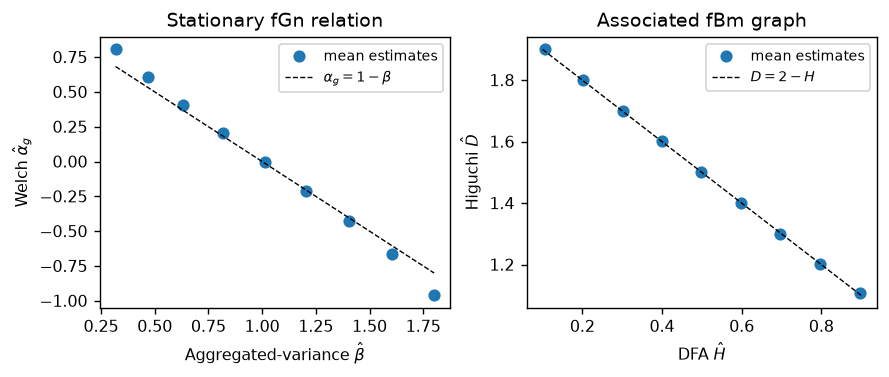

In [10]:
g=summary[(summary.process=='Davies-Harte')&(summary.N==2**14)]
p=g.pivot(index='H',columns='estimator',values='mean')
fig,axs=plt.subplots(1,2,figsize=(7,2.9),layout='constrained')
axs[0].plot(p.beta_aggregate,p.alpha_welch,'o',label='mean estimates')
b=np.linspace(p.beta_aggregate.min(),p.beta_aggregate.max(),100)
axs[0].plot(b,1-b,'k--',lw=.8,label=r'$\alpha_g=1-\beta$')
axs[0].set(xlabel=r'Aggregated-variance $\hat\beta$',ylabel=r'Welch $\hat\alpha_g$',
           title='Stationary fGn relation')
axs[1].plot(p.H_dfa,p.D_higuchi,'o',label='mean estimates')
h=np.linspace(.1,.9,100)
axs[1].plot(h,2-h,'k--',lw=.8,label=r'$D=2-H$')
axs[1].set(xlabel=r'DFA $\hat H$',ylabel=r'Higuchi $\hat D$',
           title='Associated fBm graph')
for ax in axs: ax.legend(fontsize=8)
fig.savefig(FIGURES/'relation_planes.pdf');plt.show()

### H-equivalent discrepancies for the article

 For a more direct article summary, we transform the same five estimators to a common H scale: $\widehat H_{\rm DFA}=\widehat\alpha_{\rm DFA}$, $\widehat H_{\rm agg}=1-\widehat\beta_{\rm agg}/2$, $\widehat H_{\rm Welch}=(1+\widehat\alpha_g)/2$, $\widehat H_{\rm wav}=(1+\widehat\alpha_w)/2$, and $\widehat H_{\rm Hig}=2-\widehat D_{\rm Hig}$. For Davies–Harte synthesis at $N=2^{14}$, every pairwise difference is formed within each of the 200 realizations, then averaged for each of the nine input $H$ values. A nonzero mean difference measures estimator disagreement on the chosen finite ranges; it need not contradict a process-level identity because both estimators may be biased.

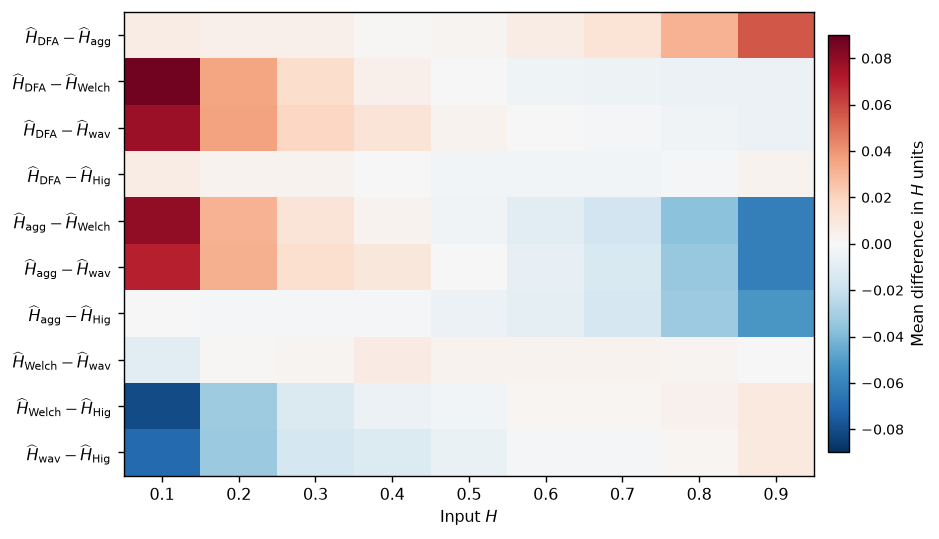

,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
DFA - aggregate,0.007,0.004,0.004,0.001,0.003,0.007,0.013,0.031,0.056
DFA - Welch,0.087,0.035,0.016,0.005,-0.000,-0.004,-0.004,-0.005,-0.005
DFA - wavelet,0.077,0.037,0.019,0.012,0.003,-0.001,-0.001,-0.003,-0.005
DFA - Higuchi,0.007,0.003,0.003,-0.000,-0.003,-0.002,-0.003,-0.002,0.003
aggregate - Welch,0.080,0.031,0.012,0.003,-0.003,-0.010,-0.017,-0.037,-0.061
aggregate - wavelet,0.070,0.032,0.014,0.010,0.000,-0.007,-0.014,-0.034,-0.061
aggregate - Higuchi,-0.001,-0.001,-0.001,-0.002,-0.005,-0.009,-0.015,-0.033,-0.053
Welch - wavelet,-0.010,0.001,0.002,0.007,0.003,0.003,0.003,0.002,0.000
Welch - Higuchi,-0.081,-0.032,-0.013,-0.005,-0.002,0.002,0.002,0.004,0.009
wavelet - Higuchi,-0.070,-0.033,-0.016,-0.012,-0.006,-0.002,-0.001,0.002,0.009


In [12]:
from itertools import combinations
from matplotlib.colors import TwoSlopeNorm

reference=estimates[(estimates.process=='Davies-Harte')&(estimates.N==2**14)].reset_index(drop=True)
h_equiv=pd.DataFrame({
    'H':reference.H,
    'DFA':reference.H_dfa,
    'aggregate':1-reference.beta_aggregate/2,
    'Welch':(1+reference.alpha_welch)/2,
    'wavelet':(1+reference.alpha_wavelet)/2,
    'Higuchi':2-reference.D_higuchi,
})
estimators=['DFA','aggregate','Welch','wavelet','Higuchi']
pairs=list(combinations(estimators,2))
records=[]
for first,second in pairs:
    difference=h_equiv[first]-h_equiv[second]
    group=(pd.DataFrame({'H':h_equiv.H,'difference':difference})
           .groupby('H').difference.agg(['count','mean','std']).reset_index())
    group['first'],group['second']=first,second
    records.append(group)
discrepancies=pd.concat(records,ignore_index=True)[['H','first','second','count','mean','std']]
assert len(discrepancies)==90 and discrepancies['count'].eq(200).all()
discrepancies.to_csv(RESULTS/'h_equivalent_discrepancies.csv',index=False)
matrix=np.vstack([discrepancies[(discrepancies['first']==first)&
                                (discrepancies['second']==second)].sort_values('H')['mean'].to_numpy()
                  for first,second in pairs])
labels={'DFA':r'\widehat H_{\mathrm{DFA}}',
        'aggregate':r'\widehat H_{\mathrm{agg}}',
        'Welch':r'\widehat H_{\mathrm{Welch}}',
        'wavelet':r'\widehat H_{\mathrm{wav}}',
        'Higuchi':r'\widehat H_{\mathrm{Hig}}'}
limit=np.ceil(np.abs(matrix).max()*100)/100
fig,ax=plt.subplots(figsize=(7.4,4.2),layout='constrained')
im=ax.imshow(matrix,aspect='auto',cmap='RdBu_r',
             norm=TwoSlopeNorm(vcenter=0,vmin=-limit,vmax=limit),interpolation='nearest')
ax.set_xticks(np.arange(len(H_VALUES)),[f'{h:.1f}' for h in H_VALUES])
ax.set_yticks(np.arange(len(pairs)),
              [f'${labels[first]}-{labels[second]}$' for first,second in pairs])
ax.set_xlabel(r'Input $H$')
ax.tick_params(axis='both',labelsize=9)
bar=fig.colorbar(im,ax=ax,pad=.02,shrink=.9)
bar.set_label(r'Mean difference in $H$ units',fontsize=9)
bar.ax.tick_params(labelsize=8)
fig.savefig(FIGURES/'h_discrepancy_heatmap.pdf');plt.show()
display(pd.DataFrame(matrix,index=[f'{a} - {b}' for a,b in pairs],columns=H_VALUES).round(3))

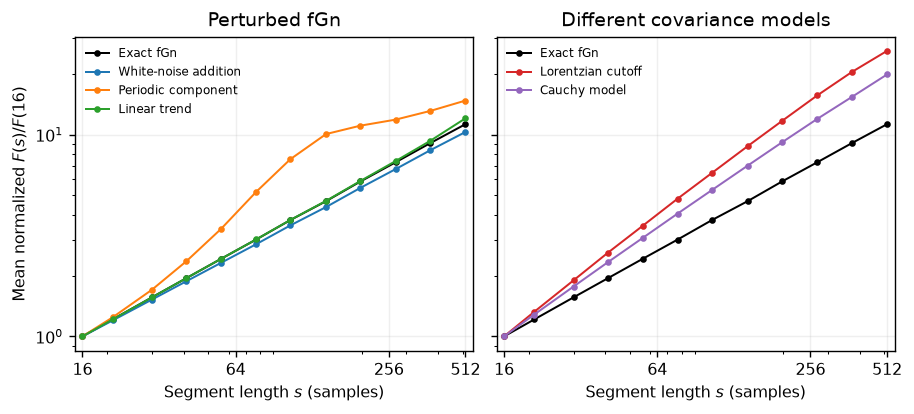

In [13]:
mean_curves=contrast_curves.groupby(['process','scale'],as_index=False).normalized_fluctuation.mean()
groups=(('reference','additive white noise','periodic component','linear trend'),
        ('reference','Lorentzian 1/f cutoff','Cauchy local/global'))
colors={'reference':'black','additive white noise':'tab:blue',
        'periodic component':'tab:orange','linear trend':'tab:green',
        'Lorentzian 1/f cutoff':'tab:red','Cauchy local/global':'tab:purple'}
labels={'reference':'Exact fGn','additive white noise':'White-noise addition',
        'periodic component':'Periodic component','linear trend':'Linear trend',
        'Lorentzian 1/f cutoff':'Lorentzian cutoff','Cauchy local/global':'Cauchy model'}
fig,axs=plt.subplots(1,2,figsize=(7.2,3.2),layout='constrained',sharey=True)
for ax,names,title in zip(axs,groups,('Perturbed fGn','Different covariance models')):
    for name in names:
        part=mean_curves[mean_curves.process==name]
        ax.loglog(part.scale,part.normalized_fluctuation,'o-',color=colors[name],
                  ms=2.8,lw=1.15,label=labels[name])
    ax.set(xlabel='Segment length $s$ (samples)',title=title,xlim=(15,550))
    ax.set_xticks([16,64,256,512],labels=['16','64','256','512'])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(which='major',alpha=.2)
    ax.legend(fontsize=6.7,loc='upper left',frameon=False)
axs[0].set_ylabel(r'Mean normalized $F(s)/F(16)$')
fig.savefig(FIGURES/'contrasts.pdf');plt.show()

## Interpretation limits

The tables and figures above are the measured output. In the article we report selected values from these saved tables. ACF fits have no positive-tail meaning at $H\le0.5$. Nonstationary fBm periodogram slopes and finite-grid graph box counts are operational estimates with finite-scale bias. Bootstrap intervals reflect simulation variability within the specified model, not uncertainty about the model itself. The original PDF's assertion that DFA and wavelets are uniformly most robust and R/S is biased is treated as a hypothesis, not assumed.